In [36]:
# This Python 3 environment comes with many helpful analytics libraries installed

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are now expected on the local filesystem. Set LOCAL_DATA_DIR
# (or rely on the notebook's working directory) to point to the folder that
# contains data.csv, predict.csv, etc.

import os
from pathlib import Path


import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit



In [37]:
# Show every column instead of truncating with "..."
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

DATA_DIR = Path(os.environ.get('LOCAL_DATA_DIR', 'data'))
df = pd.read_csv(DATA_DIR / 'data.csv')
print(df.shape)
df.head()

(1412, 51)


,yearID,teamID,G,R,AB,H,2B,3B,HR,BB,SO,SB,RA,ER,ERA,CG,SHO,SV,IPouts,HA,HRA,BBA,SOA,E,DP,FP,mlb_rpg,era_1,era_2,era_3,era_4,era_5,era_6,era_7,era_8,decade_1910,decade_1920,decade_1930,decade_1940,decade_1950,decade_1960,decade_1970,decade_1980,decade_1990,decade_2000,decade_2010,W,ID,year_label,decade_label,win_bins
0,1935,BOS,154,718,5288,1458,281,63,69,609,470.0,91,732,619,4.05,82,6,11,4128,1520,67,520,470,190,136.0,0.969,4.864690,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,78,317,1935,1930s,3
1,1993,TEX,162,835,5510,1472,284,39,181,483,984.0,113,751,684,4.28,20,6,45,4314,1476,144,562,957,130,145.0,0.979,4.597620,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,86,2162,1993,1990s,3
2,2016,SEA,162,768,5583,1446,251,17,223,506,1288.0,56,707,647,4.00,2,8,49,4371,1410,213,460,1318,89,158.0,0.985,4.477759,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,86,1895,2016,2010s,3
3,1938,CHN,154,713,5333,1435,242,70,65,522,476.0,49,598,523,3.37,67,16,18,4188,1414,71,454,583,135,151.0,0.978,4.902046,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,89,428,1938,1930s,3
4,1996,BOS,162,928,5756,1631,308,31,209,642,1020.0,91,921,810,5.00,17,5,37,4374,1606,185,722,1165,135,152.0,0.978,5.035509,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,85,375,1996,1990s,3


In [10]:
list(df.columns)

['yearID',
 'teamID',
 'G',
 'R',
 'AB',
 'H',
 '2B',
 '3B',
 'HR',
 'BB',
 'SO',
 'SB',
 'RA',
 'ER',
 'ERA',
 'CG',
 'SHO',
 'SV',
 'IPouts',
 'HA',
 'HRA',
 'BBA',
 'SOA',
 'E',
 'DP',
 'FP',
 'mlb_rpg',
 'era_1',
 'era_2',
 'era_3',
 'era_4',
 'era_5',
 'era_6',
 'era_7',
 'era_8',
 'decade_1910',
 'decade_1920',
 'decade_1930',
 'decade_1940',
 'decade_1950',
 'decade_1960',
 'decade_1970',
 'decade_1980',
 'decade_1990',
 'decade_2000',
 'decade_2010',
 'W',
 'ID',
 'year_label',
 'decade_label',
 'win_bins']

In [38]:
pred = pd.read_csv(DATA_DIR / 'predict.csv')
print(pred.shape)
pred.head()

(400, 47)


,teamID,G,R,AB,H,2B,3B,HR,BB,SO,SB,RA,ER,ERA,CG,SHO,SV,IPouts,HA,HRA,BBA,SOA,E,DP,FP,mlb_rpg,era_1,era_2,era_3,era_4,era_5,era_6,era_7,era_8,decade_1910,decade_1920,decade_1930,decade_1940,decade_1950,decade_1960,decade_1970,decade_1980,decade_1990,decade_2000,decade_2010,ID,decade_label
0,PHI,156,623,5241,1311,213,44,117,534,758.0,57,656,590,3.79,54,9,23,4203,1363,139,412,858,136,117.0,0.976,4.306073,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,1649,1950s
1,MIL,162,640,5474,1381,238,43,157,407,1183.0,142,687,615,3.84,4,15,40,4328,1401,175,466,1125,114,153.0,0.981,4.165981,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,1223,2010s
2,CLE,157,921,5646,1715,357,82,123,514,470.0,66,862,745,4.83,74,6,12,4167,1604,73,607,619,182,154.0,0.970,5.188207,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,748,1930s
3,PIT,153,743,5415,1543,255,90,66,457,437.0,30,647,519,3.42,76,15,11,4095,1428,63,312,549,190,94.0,0.968,4.864690,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,1735,1930s
4,CLE,163,761,5643,1498,222,39,123,600,815.0,126,766,694,4.26,21,7,35,4401,1523,141,545,803,146,163.0,0.977,4.256770,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,794,1980s


In [12]:
list(pred.columns)

['teamID',
 'G',
 'R',
 'AB',
 'H',
 '2B',
 '3B',
 'HR',
 'BB',
 'SO',
 'SB',
 'RA',
 'ER',
 'ERA',
 'CG',
 'SHO',
 'SV',
 'IPouts',
 'HA',
 'HRA',
 'BBA',
 'SOA',
 'E',
 'DP',
 'FP',
 'mlb_rpg',
 'era_1',
 'era_2',
 'era_3',
 'era_4',
 'era_5',
 'era_6',
 'era_7',
 'era_8',
 'decade_1910',
 'decade_1920',
 'decade_1930',
 'decade_1940',
 'decade_1950',
 'decade_1960',
 'decade_1970',
 'decade_1980',
 'decade_1990',
 'decade_2000',
 'decade_2010',
 'ID',
 'decade_label']

In [39]:
# Columns that differ between the two files
print('In data.csv only:   ', [c for c in df.columns if c not in pred.columns])
print('In predict.csv only:', [c for c in pred.columns if c not in df.columns])

In data.csv only:    ['yearID', 'W', 'year_label', 'win_bins']
In predict.csv only: []


In [40]:
# Use every numeric/boolean column shared by data.csv and predict.csv
# (drops the target, identifiers and text labels automatically)
exclude_cols = {'W', 'ID', 'yearID', 'teamID', 'year_label', 'decade_label', 'win_bins'}

shared_cols = [col for col in df.columns if col in pred.columns]
available_features = [
    col for col in df[shared_cols].select_dtypes(include=['number', 'bool']).columns
    if col not in exclude_cols
]
print(f"Number of available features: {len(available_features)}")

# Separate features and target variable
X = df[available_features]
y = df['W']

# Perform the split (adjust test_size / random_state as needed)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% for testing
    random_state=42    # ensures reproducibility
)

Number of available features: 44


In [41]:
# Scale features
# Identify columns to exclude from scaling (one-hot encoded and label columns)
one_hot_cols = [col for col in X_train.columns if col.startswith(('era_', 'decade_'))]
other_cols = [col for col in X_train.columns if col not in one_hot_cols]

# Scale only non-one-hot features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[other_cols] = scaler.fit_transform(X_train[other_cols])
X_test_scaled[other_cols] = scaler.transform(X_test[other_cols])

In [42]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
     'Ridge': (make_pipeline(StandardScaler(), Ridge()),
               {'ridge__alpha': [0.01, 0.1, 1, 3, 10, 30, 100]}),
    'Random Forest': (RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1),
                      {'min_samples_leaf': [1, 3, 5], 'max_features': [0.3, 0.6, 1.0]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42),
                          {'n_estimators': [200, 500, 1000], 'learning_rate': [0.01, 0.03, 0.1],
                           'max_depth': [2, 3]}),
}

results, fitted = [], {}
for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1)
    search.fit(X_train_scaled, y_train)
    fitted[name] = search
    test_pred = search.predict(X_test_scaled)
    results.append({
        'Model': name,
        'CV MAE': -search.best_score_,
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred),
        'Best settings': search.best_params_,
    })

results_df = pd.DataFrame(results).sort_values('CV MAE').reset_index(drop=True)
results_df

,Model,CV MAE,Test MAE,Test RMSE,Test R²,Best settings
0,Ridge,2.824000,2.701883,3.330487,0.930585,{'ridge__alpha': 1}
1,Gradient Boosting,3.174659,3.203363,4.033725,0.898176,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
2,Random Forest,3.500662,3.296012,4.180459,0.890634,"{'max_features': 1.0, 'min_samples_leaf': 3}"


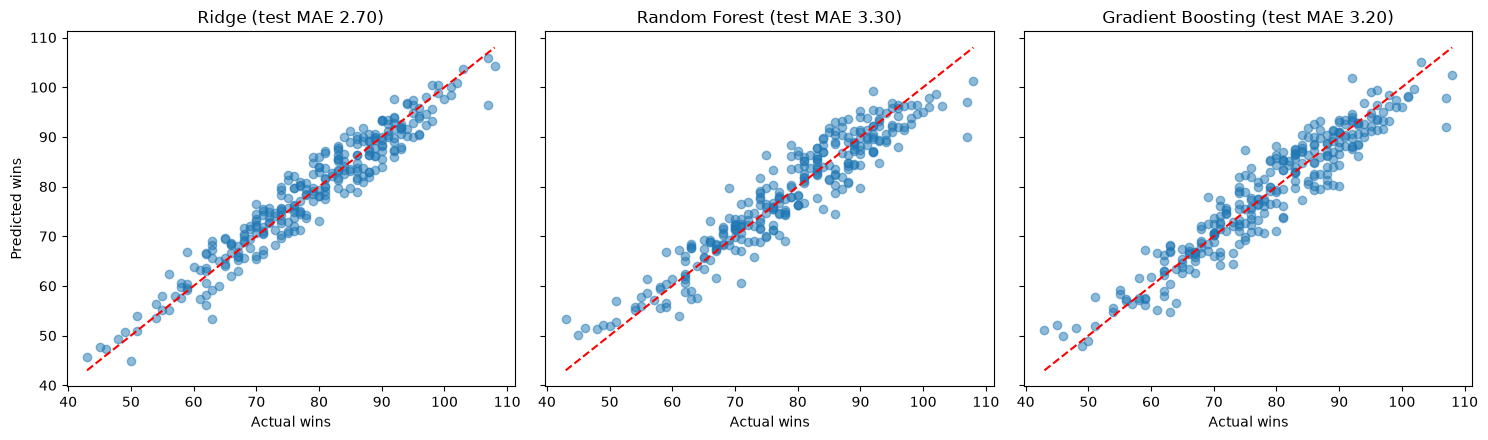

In [43]:
# Actual vs predicted on the held-out test seasons
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    p = fitted[name].predict(X_test_scaled)
    ax.scatter(y_test, p, alpha=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    ax.set_title(f'{name} (test MAE {mean_absolute_error(y_test, p):.2f})')
    ax.set_xlabel('Actual wins')
axes[0].set_ylabel('Predicted wins')
plt.tight_layout()
plt.show()

In [47]:
def add_features(d):
    """Engineered features based on 'wins = runs scored vs runs allowed'."""
    d = d.copy()
    d['R_per_G'] = d['R'] / d['G']                  # runs scored per game
    d['RA_per_G'] = d['RA'] / d['G']                # runs allowed per game
    d['RD_per_G'] = (d['R'] - d['RA']) / d['G']     # run differential per game
    # Pythagorean expectation: a classic baseball formula for expected wins
    d['pyth_W'] = d['G'] * d['R']**1.83 / (d['R']**1.83 + d['RA']**1.83)
    return d

best_name = results_df.loc[0, 'Model']
print('Best model by CV MAE:', best_name)

train_full = add_features(df).sort_values('yearID').reset_index(drop=True)
predict_fe = add_features(pred)

exclude = {'W', 'ID', 'teamID', 'win_bins', 'yearID', 'year_label', 'decade_label'}
features = [c for c in predict_fe.columns if c not in exclude]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
best_model, best_grid = models[best_name]
final_search = GridSearchCV(best_model, best_grid, cv=cv,
                            scoring='neg_mean_absolute_error', n_jobs=-1)
final_search.fit(train_full[features], train_full['W'])
print('Final settings:', final_search.best_params_)

predict_preds = final_search.predict(predict_fe[features])
submission = pd.DataFrame({'ID': predict_fe['ID'], 'W': np.round(predict_preds).astype(int)})
submission.to_csv('submission.csv', index=False)
print(f'Saved submission.csv ({len(submission)} rows)')
submission.head()

Best model by CV MAE: Ridge


Final settings: {'ridge__alpha': 1}
Saved submission.csv (400 rows)


,ID,W
0,1649,77
1,1223,77
2,748,83
3,1735,85
4,794,79
